# n296_stage3_3 영양 모델 — food_split_txt 3개 분할 학습 결과

`/home/leehogwang/food_split_txt` 의 분할 3개(**122_1_forseen**, **122_2_forunseen**, **n5k**)를 각각 따로 써서
n296_stage3_3 의 영양 모델(`n296.model.Stage3NutritionModel`, 텍스트 임베딩 + ConvNeXt-Base + FFT 주파수 분기)을 3번 학습한 결과다.
상세 정리는 `REPORT.md` 에 있다.

- **PMAE(G)** = Σ|예측−정답| ÷ Σ정답 × 100 (%). **G4** = 칼로리·지방·단백질·탄수화물 PMAE 평균 (주 지표, 낮을수록 좋음).
- test 조건: **text_gt** = 정답 텍스트(122 음식명, N5k 재료 목록), **text_gemini** = Gemini 가 사진만 보고 추정한 텍스트, **baseline** = train 평균값을 모두에 예측.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager as fm
from pathlib import Path
EXP = Path('/home/leehogwang/food_b/experiments/split_txt_3runs')
for f in Path.home().joinpath('.fonts').glob('NanumGothic*.ttf'): fm.fontManager.addfont(str(f))
mpl.rcParams.update({'font.family': 'NanumGothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8986', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'legend.frameon': False})
BLUE, ORANGE, AQUA, YELLOW, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8986'
RUNS = ['122_1_forseen', '122_2_forunseen', 'n5k']
LABEL = {'122_1_forseen': '122 seen (사진 단위)', '122_2_forunseen': '122 unseen (음식 단위)', 'n5k': 'Nutrition5k'}
KEYS = ['calories', 'fat', 'protein', 'carb', 'mass']; KO = dict(zip(KEYS, ['칼로리', '지방', '단백질', '탄수화물', '중량']))
recs = json.loads((EXP / 'records.json').read_text()); S = json.loads((EXP / 'splits.json').read_text())
R = {r: json.loads((EXP / 'runs' / r / 'result.json').read_text()) for r in RUNS}
H = {r: pd.read_csv(EXP / 'runs' / r / 'history.csv') for r in RUNS}
PR = {(r, t): np.load(EXP / 'runs' / r / f'preds_text_{t}.npz') for r in RUNS for t in ('gt', 'gemini')}
gem = {}
for l in open(EXP / 'gemini_pred.jsonl'):
    j = json.loads(l); gem[j['id']] = j
def G(P, T): P, T = np.asarray(P, float), np.asarray(T, float); return np.abs(P - T).sum(0) / T.sum(0) * 100
def G4(P, T): return float(G(P, T)[:4].mean())

## 1. 데이터 구성

,분할,set,사진/접시 수,음식 수,촬영 시점
0,122_1_forseen,train,31484,78,"{'side': 15865, 'top': 15619}"
1,122_1_forseen,val,3423,78,"{'side': 1730, 'top': 1693}"
2,122_1_forseen,test,4387,78,"{'top': 2249, 'side': 2138}"
3,122_2_forunseen,train,10840,44,{'side': 10840}
4,122_2_forunseen,val,2989,12,{'side': 2989}
5,122_2_forunseen,test,5884,23,{'side': 5884}
6,n5k,train,3641,-,"{'overhead': 2483, 'camera_A': 1101, 'camera_B..."
7,n5k,val,405,-,"{'overhead': 271, 'camera_A': 121, 'camera_B':..."
8,n5k,test,708,-,"{'overhead': 506, 'camera_A': 193, 'camera_B':..."


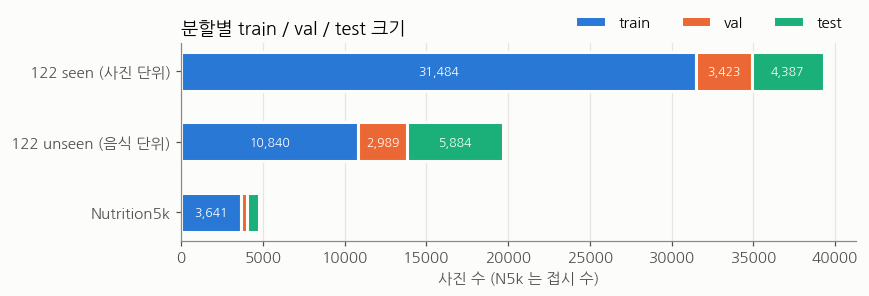

In [2]:
rows = []
for r in RUNS:
    for s in ('train', 'val', 'test'):
        ids = S[r][s]; v = pd.Series([recs[i]['view'] for i in ids]).value_counts().to_dict()
        rows.append({'분할': r, 'set': s, '사진/접시 수': len(ids),
                     '음식 수': len({recs[i].get('food') for i in ids}) if r != 'n5k' else '-', '촬영 시점': v})
df = pd.DataFrame(rows); display(df)
fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(3)
for s, c in zip(('train', 'val', 'test'), (BLUE, ORANGE, AQUA)):
    n = np.array([len(S[r][s]) for r in RUNS])
    ax.barh([LABEL[r] for r in RUNS], n, left=left, color=c, label=s, height=0.55, edgecolor='#fcfcfb', linewidth=2)
    for y, (l, w) in enumerate(zip(left, n)):
        if w > 1500: ax.text(l + w / 2, y, f'{w:,}', ha='center', va='center', fontsize=8, color='white')
    left += n
ax.set_xlabel('사진 수 (N5k 는 접시 수)'); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
ax.legend(ncol=3, loc='lower right', bbox_to_anchor=(1, 1)); ax.set_title('분할별 train / val / test 크기', loc='left'); plt.tight_layout(); plt.show()

## 2. 학습 곡선
검증 G4 (정답 텍스트) 와 학습 손실. 점선 = best epoch (이 체크포인트로 test 평가).

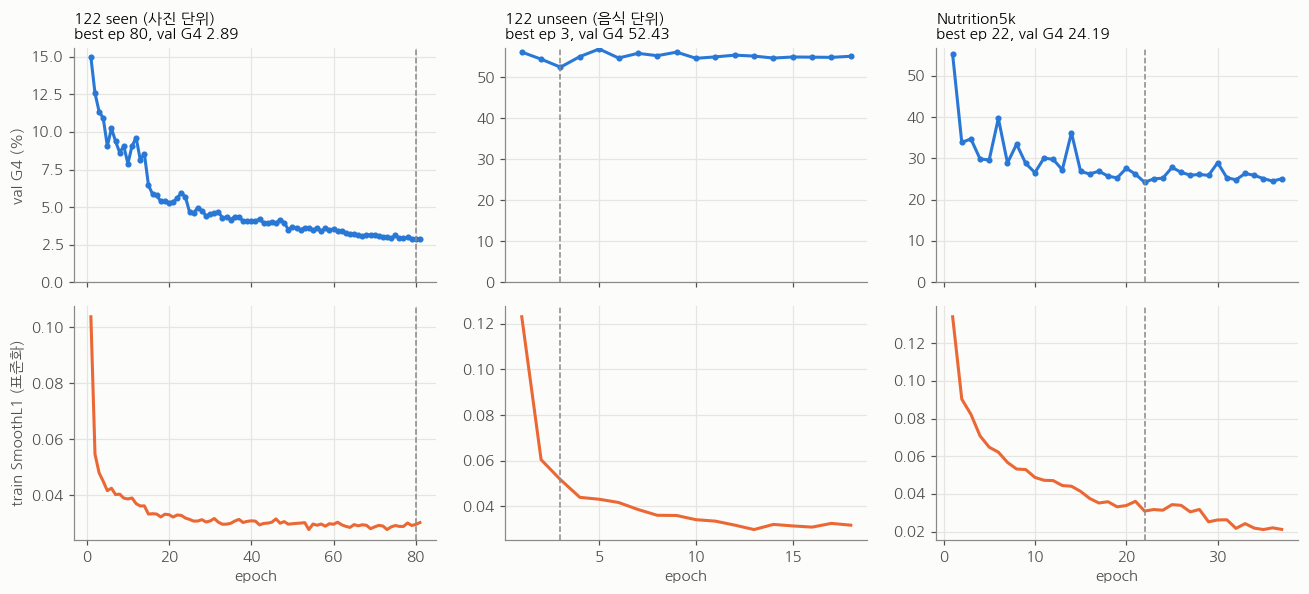

,best epoch,실행 epoch,시간(분),시간 상한 도달,val G4
122_1_forseen,80,81,180.2,True,2.89
122_2_forunseen,3,18,26.5,False,52.43
n5k,22,37,23.3,False,24.19


In [3]:
fig, axs = plt.subplots(2, 3, figsize=(12, 5.5), sharex='col')
for k, r in enumerate(RUNS):
    h = H[r]; b = R[r]['best_epoch']
    axs[0, k].plot(h.epoch, h.val_G4, color=BLUE, lw=2, marker='o', ms=3)
    axs[0, k].axvline(b, color=GRAY, ls='--', lw=1); axs[0, k].set_title(f"{LABEL[r]}\nbest ep {b}, val G4 {R[r]['val_G4']:.2f}", loc='left', fontsize=10)
    axs[1, k].plot(h.epoch, h.train_loss, color=ORANGE, lw=2); axs[1, k].axvline(b, color=GRAY, ls='--', lw=1); axs[1, k].set_xlabel('epoch')
axs[0, 0].set_ylabel('val G4 (%)'); axs[1, 0].set_ylabel('train SmoothL1 (표준화)')
for a in axs[0]: a.set_ylim(0, None)
plt.tight_layout(); plt.show()
display(pd.DataFrame({r: {'best epoch': R[r]['best_epoch'], '실행 epoch': R[r]['epochs_run'], '시간(분)': R[r]['minutes'],
    '시간 상한 도달': R[r]['time_capped'], 'val G4': R[r]['val_G4']} for r in RUNS}).T)

## 3. test 성능 요약

,분할,조건,n,G4,A4,칼로리,지방,단백질,탄수화물,중량,mean_pmae(칼·지·단)
0,122 seen (사진 단위),정답 텍스트,4387,2.82,4.43,2.64,3.01,2.83,2.81,2.59,2.83
1,122 seen (사진 단위),Gemini 텍스트,4387,4.63,7.01,3.74,5.25,5.09,4.44,4.07,4.69
2,122 seen (사진 단위),train 평균값,4387,73.36,234.37,63.72,81.86,70.04,77.81,69.92,71.87
3,122 unseen (음식 단위),정답 텍스트,5884,50.77,84.20,43.59,60.89,51.86,46.74,35.84,52.11
4,122 unseen (음식 단위),Gemini 텍스트,5884,50.25,83.61,43.54,59.37,51.92,46.16,36.54,51.61
5,122 unseen (음식 단위),train 평균값,5884,69.63,164.46,60.73,76.56,70.03,71.20,63.71,69.11
6,Nutrition5k,정답 텍스트,708,31.39,35.21,28.57,38.81,27.44,30.75,24.66,31.60
7,Nutrition5k,Gemini 텍스트,708,35.23,44.65,30.68,44.67,32.47,33.09,26.01,35.94
8,Nutrition5k,train 평균값,708,81.78,287.33,73.29,89.67,88.99,75.17,64.42,83.98


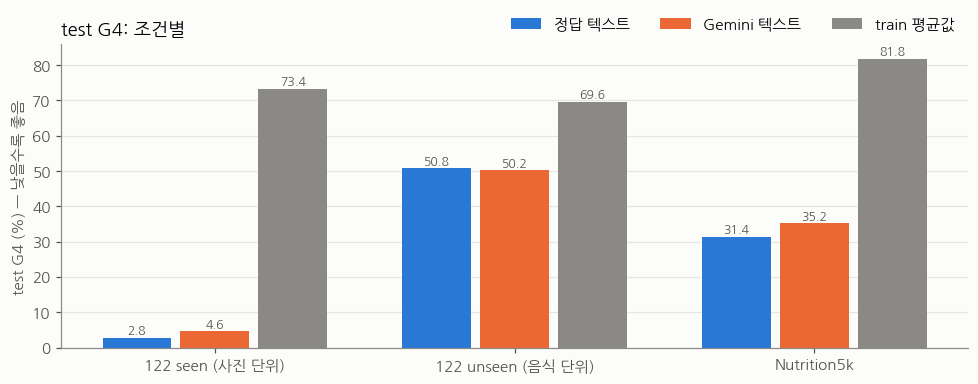

In [4]:
rows = []
for r in RUNS:
    for c, nm in (('text_gt', '정답 텍스트'), ('text_gemini', 'Gemini 텍스트'), ('baseline_train_mean', 'train 평균값')):
        m = R[r]['test'][c]; rows.append({'분할': LABEL[r], '조건': nm, 'n': m['n'], 'G4': m['G4'], 'A4': m['A4'],
            **{KO[k]: m['G'][k] for k in KEYS}, 'mean_pmae(칼·지·단)': m['mean_pmae']})
T = pd.DataFrame(rows); display(T.round(2))
fig, ax = plt.subplots(figsize=(9, 3.6)); w = 0.26; x = np.arange(3)
for j, (c, nm, col) in enumerate((('text_gt', '정답 텍스트', BLUE), ('text_gemini', 'Gemini 텍스트', ORANGE), ('baseline_train_mean', 'train 평균값', GRAY))):
    v = [R[r]['test'][c]['G4'] for r in RUNS]
    bs = ax.bar(x + (j - 1) * w, v, w - 0.03, color=col, label=nm)
    for b, vv in zip(bs, v): ax.text(b.get_x() + b.get_width() / 2, vv + 1, f'{vv:.1f}', ha='center', fontsize=8, color='#52514e')
ax.set_xticks(x, [LABEL[r] for r in RUNS]); ax.set_ylabel('test G4 (%) — 낮을수록 좋음'); ax.grid(axis='x', visible=False)
ax.legend(ncol=3, loc='lower right', bbox_to_anchor=(1, 1)); ax.set_title('test G4: 조건별', loc='left'); plt.tight_layout(); plt.show()

### 3.1 영양소별 PMAE (정답 텍스트 / Gemini 텍스트)

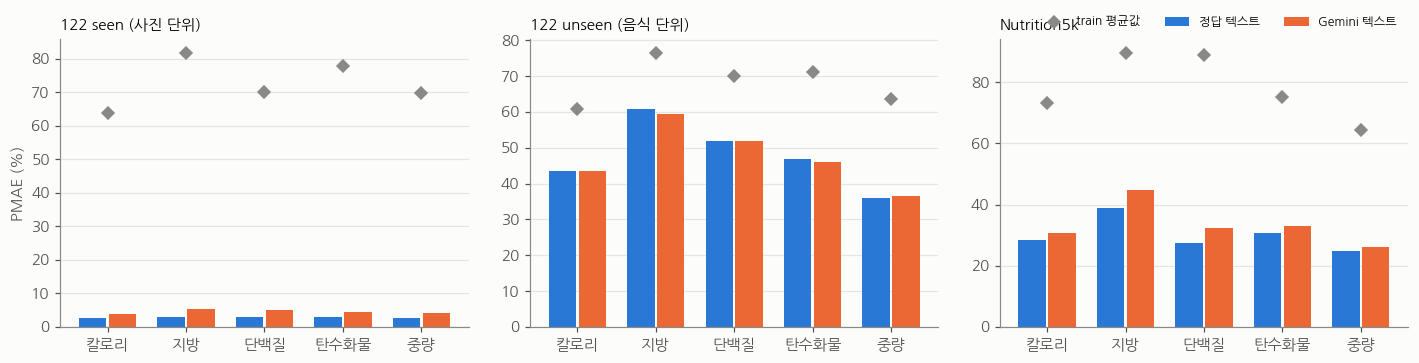

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4), sharey=False)
x = np.arange(5); w = 0.38
for a, r in zip(axs, RUNS):
    for j, (c, nm, col) in enumerate((('text_gt', '정답 텍스트', BLUE), ('text_gemini', 'Gemini 텍스트', ORANGE))):
        v = [R[r]['test'][c]['G'][k] for k in KEYS]; a.bar(x + (j - .5) * w, v, w - 0.03, color=col, label=nm)
    a.plot(x, [R[r]['test']['baseline_train_mean']['G'][k] for k in KEYS], 'D', color=GRAY, ms=6, label='train 평균값')
    a.set_xticks(x, [KO[k] for k in KEYS]); a.set_title(LABEL[r], loc='left', fontsize=10); a.grid(axis='x', visible=False)
axs[0].set_ylabel('PMAE (%)'); axs[-1].legend(loc='lower right', bbox_to_anchor=(1, 1), ncol=3, fontsize=8); plt.tight_layout(); plt.show()

## 4. 예측 vs 정답 (칼로리, 정답 텍스트)
대각선 = 완벽한 예측. 축은 각 분할의 99 백분위까지.

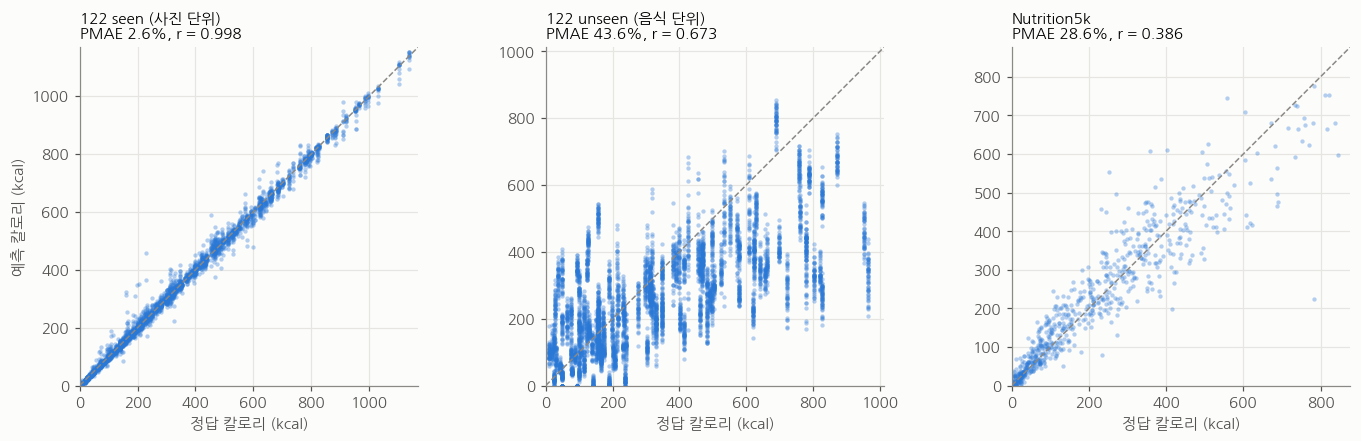

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for a, r in zip(axs, RUNS):
    d = PR[(r, 'gt')]; p, t = d['pred'][:, 0], d['target'][:, 0]; lim = np.percentile(np.r_[p, t], 99) * 1.05
    a.scatter(t, p, s=8, color=BLUE, alpha=0.35, linewidths=0); a.plot([0, lim], [0, lim], color=GRAY, lw=1, ls='--')
    a.set_xlim(0, lim); a.set_ylim(0, lim); a.set_xlabel('정답 칼로리 (kcal)'); a.set_aspect('equal')
    cc = np.corrcoef(p, t)[0, 1]; a.set_title(f'{LABEL[r]}\nPMAE {G(d["pred"], d["target"])[0]:.1f}%, r = {cc:.3f}', loc='left', fontsize=10)
axs[0].set_ylabel('예측 칼로리 (kcal)'); plt.tight_layout(); plt.show()

## 5. AIHub 122 상세
### 5.1 양 등급(Q1~Q5)별 G4 — 정답은 영양DB 1인분 × Q 비율(0.25~1.25)

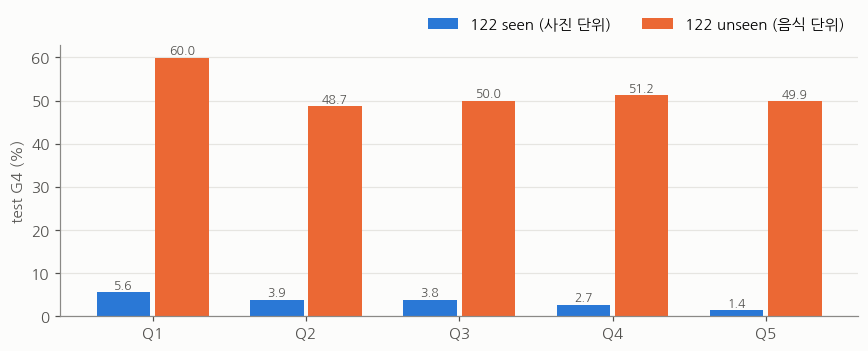

Q,Q1,Q2,Q3,Q4,Q5
분할,,,,,
122_1_forseen,5.55,3.88,3.82,2.69,1.37
122_2_forunseen,59.98,48.66,49.97,51.19,49.91


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.3)); w = 0.38; x = np.arange(5); rows = []
for j, (r, col) in enumerate((('122_1_forseen', BLUE), ('122_2_forunseen', ORANGE))):
    d = PR[(r, 'gt')]; q = np.array([recs[i]['q'] for i in d['id']]); v = []
    for k in range(5):
        m = q == k; v.append(G4(d['pred'][m], d['target'][m])); rows.append({'분할': r, 'Q': f'Q{k+1}', 'n': int(m.sum()), 'G4': round(v[-1], 2)})
    bs = ax.bar(x + (j - .5) * w, v, w - 0.03, color=col, label=LABEL[r])
    for b, vv in zip(bs, v): ax.text(b.get_x() + b.get_width() / 2, vv + 0.8, f'{vv:.1f}', ha='center', fontsize=8, color='#52514e')
ax.set_xticks(x, [f'Q{k+1}' for k in range(5)]); ax.set_ylabel('test G4 (%)'); ax.grid(axis='x', visible=False)
ax.legend(ncol=2, loc='lower right', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).pivot(index='분할', columns='Q', values='G4'))

### 5.2 122 seen: 촬영 시점(side / top)별 G4

In [8]:
d = PR[('122_1_forseen', 'gt')]; dg = PR[('122_1_forseen', 'gemini')]; v = np.array([recs[i]['view'] for i in d['id']])
rows = []
for vv in ('side', 'top'):
    m = v == vv; mg = m & dg['ok']
    rows.append({'시점': vv, 'n': int(m.sum()), 'G4 정답 텍스트': round(G4(d['pred'][m], d['target'][m]), 2),
                 'G4 Gemini 텍스트': round(G4(dg['pred'][mg], dg['target'][mg]), 2)})
display(pd.DataFrame(rows))

,시점,n,G4 정답 텍스트,G4 Gemini 텍스트
0,side,2138,3.08,5.03
1,top,2249,2.59,4.26


### 5.3 122 unseen: test 음식별 G4 (학습에 없던 23종)

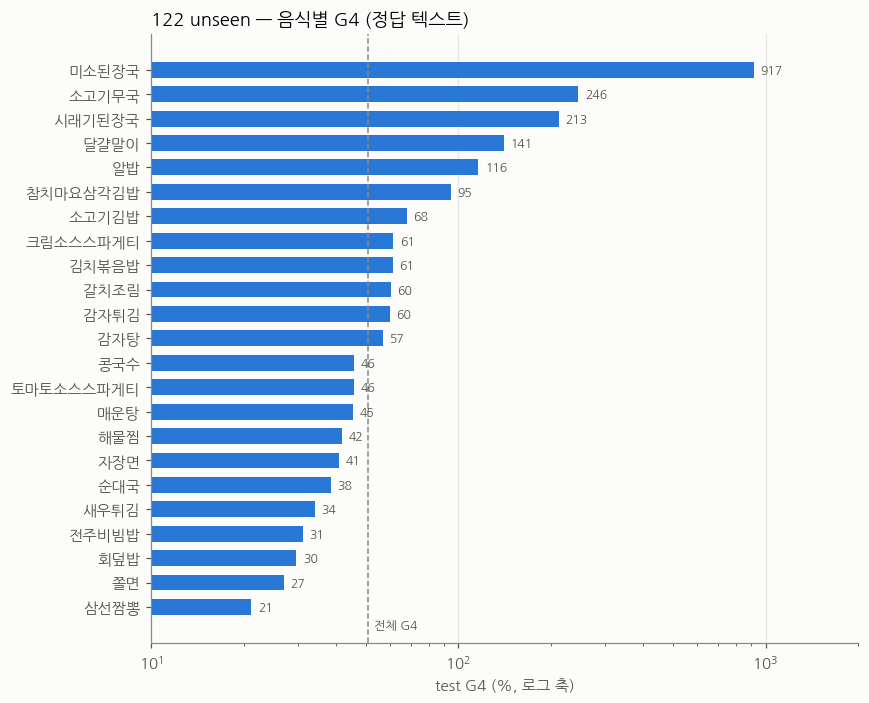

,음식,n,G4,칼로리 PMAE
0,삼선짬뽕,248,21.20,18.34
1,쫄면,245,27.03,34.52
2,회덮밥,251,29.71,31.12
3,전주비빔밥,257,31.17,40.56
4,새우튀김,246,34.11,15.00
5,순대국,244,38.49,14.29
6,자장면,247,40.91,35.77
7,해물찜,246,41.92,15.99
8,매운탕,237,45.39,50.36
9,토마토소스스파게티,246,45.82,46.85


In [9]:
d = PR[('122_2_forunseen', 'gt')]; f = np.array([recs[i]['food'] for i in d['id']]); rows = []
for x_ in sorted(set(f)):
    m = f == x_; rows.append({'음식': x_, 'n': int(m.sum()), 'G4': G4(d['pred'][m], d['target'][m]),
                              '칼로리 PMAE': G(d['pred'][m], d['target'][m])[0]})
pf = pd.DataFrame(rows).sort_values('G4');
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(pf['음식'], pf['G4'], color=BLUE, height=0.65)
for y, vv in enumerate(pf['G4']): ax.text(vv * 1.05, y, f'{vv:.0f}', va='center', fontsize=8, color='#52514e')
ax.axvline(R['122_2_forunseen']['test']['text_gt']['G4'], color=GRAY, ls='--', lw=1); ax.text(R['122_2_forunseen']['test']['text_gt']['G4'] * 1.05, -0.9, '전체 G4', fontsize=8, color='#52514e')
ax.set_xscale('log'); ax.set_xlim(10, 2000); ax.set_xlabel('test G4 (%, 로그 축)'); ax.grid(axis='y', visible=False); ax.set_title('122 unseen — 음식별 G4 (정답 텍스트)', loc='left'); plt.tight_layout(); plt.show()
display(pf.round(2).reset_index(drop=True))

### 5.4 Gemini 음식명 추정 정확도 (122 test)
정답 음식명과 글자가 완전히 같은 비율. 다른 이름이어도 비슷한 음식이면 임베딩이 가까울 수 있다.

In [10]:
rows = []
for r in ('122_1_forseen', '122_2_forunseen'):
    ids = S[r]['test']; ok = [gem[i]['food'].replace(' ', '') == recs[i]['food'].replace(' ', '') for i in ids if i in gem]
    rows.append({'분할': r, 'n': len(ok), '음식명 일치율 (%)': round(100 * np.mean(ok), 1)})
display(pd.DataFrame(rows))
ids = S['122_2_forunseen']['test']
ex = pd.DataFrame([{'정답': recs[i]['food'], 'Gemini': gem[i]['food']} for i in ids if i in gem]).value_counts().rename('n').reset_index()
display(ex.head(20))

,분할,n,음식명 일치율 (%)
0,122_1_forseen,4387,55.3
1,122_2_forunseen,5884,39.5


,정답,Gemini,n
0,소고기김밥,김밥,248
1,콩국수,콩국수,248
2,달걀말이,계란말이,247
3,감자튀김,감자튀김,246
4,감자튀김,웨지감자,244
5,새우튀김,새우튀김,243
6,소고기무국,소고기무국,241
7,김치볶음밥,김치볶음밥,236
8,자장면,짜장면,234
9,토마토소스스파게티,토마토스파게티,231


## 6. Nutrition5k 상세
### 6.1 촬영 시점별 (overhead = realsense 위쪽 RGB, camera_X = 측면 영상 프레임)

In [11]:
d = PR[('n5k', 'gt')]; dg = PR[('n5k', 'gemini')]; v = np.array(['overhead' if recs[i]['view'] == 'overhead' else 'side(camera)' for i in d['id']])
rows = []
for vv in ('overhead', 'side(camera)'):
    m = v == vv; mg = m & dg['ok']
    rows.append({'시점': vv, 'n': int(m.sum()), 'G4 정답 텍스트': round(G4(d['pred'][m], d['target'][m]), 2), 'G4 Gemini 텍스트': round(G4(dg['pred'][mg], dg['target'][mg]), 2)})
display(pd.DataFrame(rows))

,시점,n,G4 정답 텍스트,G4 Gemini 텍스트
0,overhead,506,22.67,26.89
1,side(camera),202,53.42,56.08


### 6.2 정답 칼로리 구간별 오차
작은 접시(칼로리 낮음)는 상대 오차가 크다.

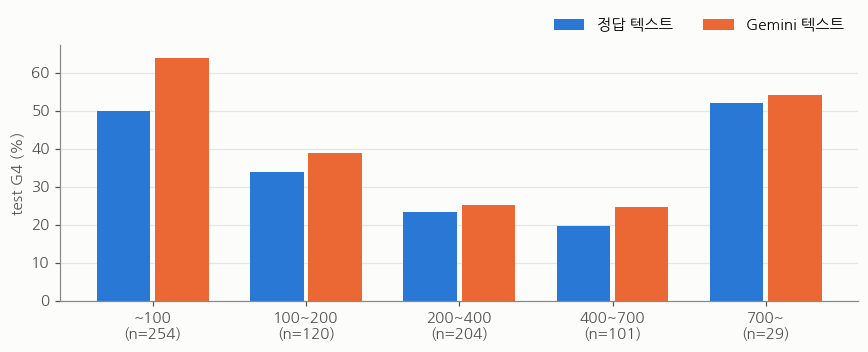

,칼로리 구간,n,G4 정답 텍스트,G4 Gemini 텍스트,칼로리 MAE (kcal)
0,~100,254,50.08,64.04,18.90
1,100~200,120,33.87,39.05,40.51
2,200~400,204,23.27,25.23,54.33
3,400~700,101,19.75,24.78,76.94
4,700~,29,52.20,54.12,783.59


In [12]:
t = d['target'][:, 0]; bins = [0, 100, 200, 400, 700, 5000]; lab = ['~100', '100~200', '200~400', '400~700', '700~']
idx = np.digitize(t, bins[1:-1]); rows = []
for k, l in enumerate(lab):
    m = idx == k
    if m.sum() == 0: continue
    rows.append({'칼로리 구간': l, 'n': int(m.sum()), 'G4 정답 텍스트': G4(d['pred'][m], d['target'][m]),
                 'G4 Gemini 텍스트': G4(dg['pred'][m & dg['ok']], dg['target'][m & dg['ok']]),
                 '칼로리 MAE (kcal)': float(np.abs(d['pred'][m, 0] - t[m]).mean())})
cb = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.3)); x = np.arange(len(cb)); w = 0.38
ax.bar(x - w / 2, cb['G4 정답 텍스트'], w - 0.03, color=BLUE, label='정답 텍스트'); ax.bar(x + w / 2, cb['G4 Gemini 텍스트'], w - 0.03, color=ORANGE, label='Gemini 텍스트')
ax.set_xticks(x, [f"{a}\n(n={n})" for a, n in zip(cb['칼로리 구간'], cb['n'])]); ax.set_ylabel('test G4 (%)'); ax.grid(axis='x', visible=False)
ax.legend(ncol=2, loc='lower right', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show(); display(cb.round(2))

### 6.3 라벨 오류로 보이는 접시
정답 9,000 kcal 이상(중량 159 g 에 지방 876 g 등 물리적으로 불가능)인 2접시. 이 둘을 빼고 다시 계산한 G4.

In [13]:
m = d['target'][:, 0] < 3000
display(pd.DataFrame([{'접시': recs[int(i)]['name'], '시점': recs[int(i)]['view'], '정답 칼로리': round(float(t_), 0), '예측 칼로리': round(float(p_), 0),
    '정답 지방(g)': round(float(f_), 0), '정답 중량(g)': round(float(w_), 0)} for i, t_, p_, f_, w_ in zip(d['id'][~m], d['target'][~m, 0], d['pred'][~m, 0], d['target'][~m, 1], d['target'][~m, 4])]))
display(pd.DataFrame([{'조건': nm, '전체 708 G4': round(G4(x['pred'][x['ok']], x['target'][x['ok']]), 2), '2접시 제외 G4': round(G4(x['pred'][m & x['ok']], x['target'][m & x['ok']]), 2)}
    for nm, x in (('정답 텍스트', d), ('Gemini 텍스트', dg))]))

,접시,시점,정답 칼로리,예측 칼로리,정답 지방(g),정답 중량(g)
0,dish_1551567573,camera_A,9486.0,569.0,876.0,159.0
1,dish_1551567508,camera_A,9170.0,54.0,853.0,7974.0


,조건,전체 708 G4,2접시 제외 G4
0,정답 텍스트,31.39,24.71
1,Gemini 텍스트,35.23,28.98


## 7. 오차가 큰 예시 (정답 텍스트, 칼로리 절대 오차 상위 8)

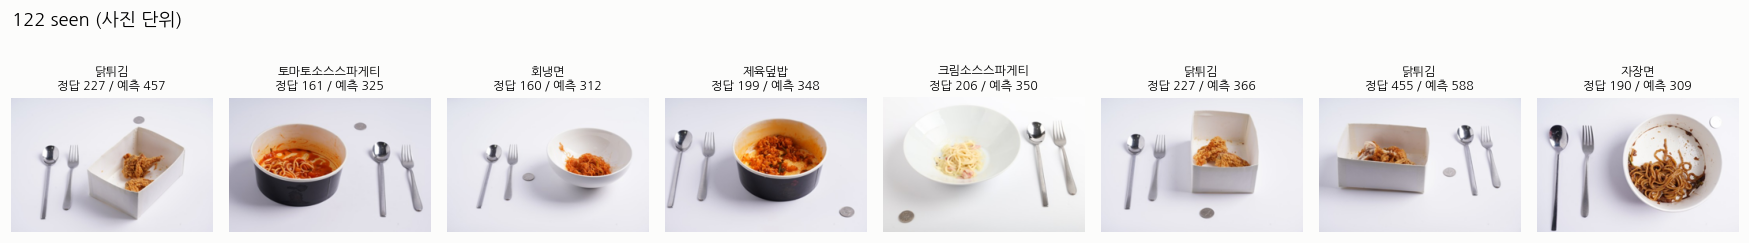

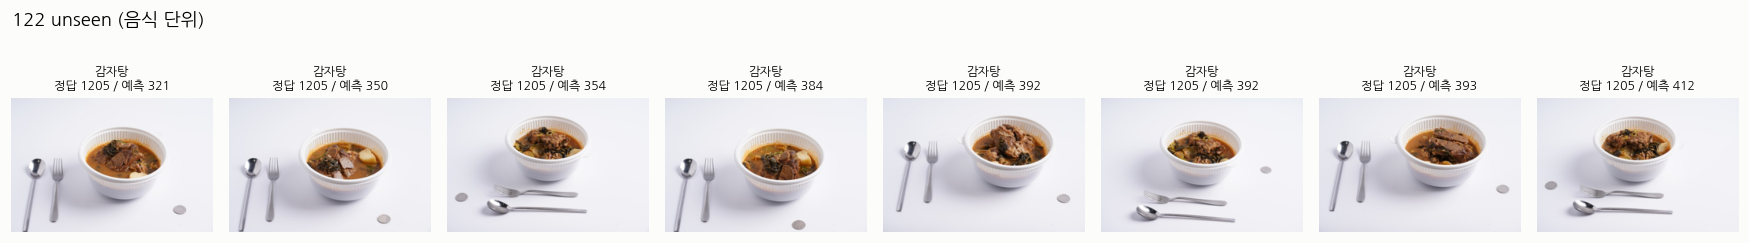

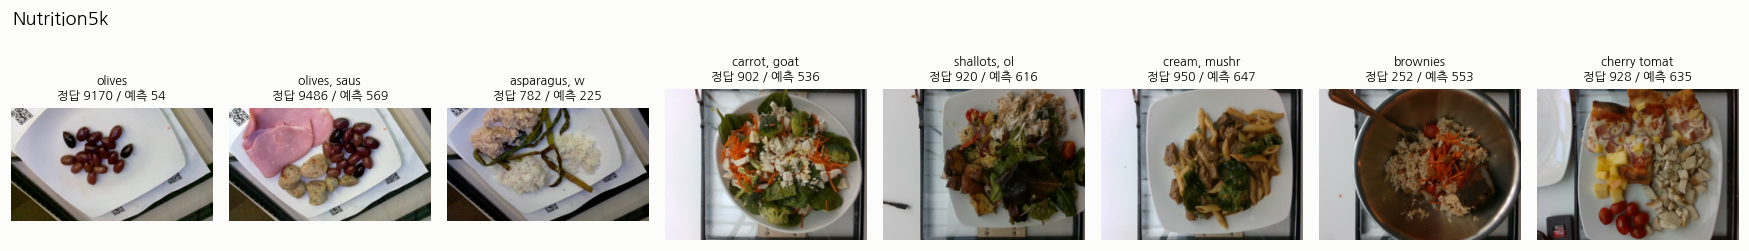

In [14]:
for r in RUNS:
    d = PR[(r, 'gt')]; e = np.abs(d['pred'][:, 0] - d['target'][:, 0]); top = np.argsort(-e)[:8]
    fig, axs = plt.subplots(1, 8, figsize=(16, 2.6))
    for a, j in zip(axs, top):
        rr = recs[int(d['id'][j])]; from PIL import Image; im = Image.open(rr['img']).convert('RGB'); im.thumbnail((256, 256)); a.imshow(im); a.axis('off')
        nm = rr.get('food') or ', '.join(dict.fromkeys(rr['ingr']))[:18]
        a.set_title(f"{nm[:12]}\n정답 {d['target'][j,0]:.0f} / 예측 {d['pred'][j,0]:.0f}", fontsize=8)
    fig.suptitle(LABEL[r], x=0.01, ha='left'); plt.tight_layout(); plt.show()